# ODE PINN Project

The aim of this project is to reinforce the theory on PINN's by building a basic PINN. For this project, we will consider the IVP given by the following differential equation:
$$ u'(t) + u(t) = 0, \hspace{3mm} u(0)=1, \hspace{3mm} t\in[0,5]$$

This project acts as a stepping stone in our learning and serves as a simplified learning model which will be useful when we tackle the next project of trying to build a neural network that solves the heat equation.

In [2]:
import torch
import matplotlib.pyplot as plt
import torch.nn as nn

## First step

We are going to use the test polynomial $v(t)=t^3-2t+1$ (since this is an easily differentiable analytic function) as a basic means of checking the computation of the derivative that is computed using PyTorch.

In [3]:
# Initialising data type and seed
torch.set_default_dtype(torch.float64)
torch.manual_seed(0)

# Building 6 evaluation points in the domain and storing them as a column vector

t = torch.linspace(0.0, 5.0, 6).reshape(-1, 1)
t.requires_grad_(True)

# Test polynomial
v = t**3 - 2*t + 1

print(t.shape)

torch.Size([6, 1])


In [4]:
# Computing derivative using PyTorch

dv_dt = torch.autograd.grad(
    outputs=v,
    inputs=t,
    grad_outputs=torch.ones_like(v),
    create_graph=True,)[0]

A brief note on the above function. torch.autgrad.grad() is the usual PyTorch function which computes the gradient through the neural network. Setting 'outputs=v' initialises the output as the test polynomial $v$, 'inputs=t' initialises the input as $t$ so that collectively they produce the gradient of $v$ with respect to $t$. Additionally, 'grad_outputs=torch.ones_like(v)' creates a tensor the same size as $v$ with all entries 1 to serve as the first term in the chain rule when calculating the following adjoints. Namely, it represents $\frac{\partial\mathcal{L}}{\partial v}=1$ but in the same tensor form as $v$ to ensure appropriate matrix multiplication. Finally, 'create_graph=True' keeps a differentiable computation of the derivative to store the gradient data, whilst still allowing further differentiate through it. This is particularly important since for when we train our PINN. Namely, 'create_graph=True' will allow the parameter gradient to pass through the computed input derivative. 

In [5]:
# Computing the exact derivative (analytic function)

dv_dt_exact = 3*t**2 - 2

# Maximum discrepancy between analytic and computed derivative

max_disc = torch.max(torch.abs(dv_dt-dv_dt_exact))

print("Maximum discrepancy between analytic and computed derivative is: " + str(max_disc))

# Decay equation residual

rv = dv_dt + v

Maximum discrepancy between analytic and computed derivative is: tensor(0., grad_fn=<MaxBackward1>)


## PINN Model

We will use the same architecture that we have used in the previous project. Namely an input, 2 hidden layers and an output with the form:

$$ 1 \rightarrow 16 \rightarrow 16 \rightarrow 1 $$

with $\tanh$ after each hidden layer and an affine output layer. We are going to use the torch.nn module which has a few more features that will be convenient for our use.

In [6]:
# Define the architecture and register its trainable layers.
# Each PINN instance retains its parameters across forward evaluations.
# Sequential applies its modules in the listed order.

torch.manual_seed(0)

class PINN(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(1, 16),
            nn.Tanh(),
            nn.Linear(16, 16),
            nn.Tanh(),
            nn.Linear(16, 1)
        )
        
    def forward(self, x):
        return self.network(x)

model = PINN()
u_pred = model(t)

# Computing the gradient of the model

du_dt = torch.autograd.grad(
    outputs=u_pred,
    inputs=t,
    grad_outputs=torch.ones_like(u_pred),
    create_graph=True,)[0]

# Differential-equation residual
def eqresidual(du_dt, u_pred):
    return(du_dt + u_pred)

# Mean squared equation residual
def mseresidual(du_dt, u_pred):
    return torch.mean((du_dt+u_pred)**2)

# Computing the initial input. We will simply call the model on our initial condition t_0=0

t0 = torch.zeros((1,1))
u0 = model(t0)

# Loss of the initial condition. We compute the mean so that it returns a scalar, same as L_eq.

def lossinit(u0):
    return ((u0-1)**2).mean()

# Total loss

loss = mseresidual(du_dt, u_pred) + lossinit(u0)

print(loss)

tensor(1.8568, grad_fn=<AddBackward0>)


In [7]:
# Creates 32 collocation points that are the midpoints of the 32 partitions splitting up [0,5]

collpoints = torch.reshape(torch.arange(start=5/64, end=5, step=5/32, dtype=torch.float64),(32,1))
collpoints.requires_grad_(True)

torch.manual_seed(0)
model=PINN()

params = tuple(model.parameters())
optimiser = torch.optim.Adam(params, lr=1e-3)

eqvalues=[]
initvalues=[]
lossvalues=[]

# Training loop

for epoch in range(1000):
    model.train()
    optimiser.zero_grad()
    ucoll = model(collpoints)
    # Recomputes gradient of collocation points
    ducoll_dt = torch.autograd.grad(
        outputs=ucoll,
        inputs=collpoints,
        grad_outputs=torch.ones_like(ucoll),
        create_graph=True,)[0]
    # Recomputes initial condition
    u0 = model(t0)
    # Loss of current model
    loss = mseresidual(ducoll_dt, ucoll) + lossinit(u0)
    loss.backward(inputs=params)
    optimiser.step()
    eqvalues.append(mseresidual(ducoll_dt, ucoll).item())
    initvalues.append(lossinit(u0).item())
    lossvalues.append(loss.item())

print("Equation loss:", eqvalues[0], "->", eqvalues[-1])
print("Initial loss:", initvalues[0], "->", initvalues[-1])
print("Total loss:", lossvalues[0], "->", lossvalues[-1])
print("Final initial prediction:", model(t0).item())

Equation loss: 0.08625904756438851 -> 0.0003592627938411654
Initial loss: 1.766555376667937 -> 9.084814300786873e-07
Total loss: 1.8528144242323255 -> 0.00036017127527124406
Final initial prediction: 0.9990489724942772


Evidently, the total loss is very low, on the order of $10^{-4}$. We could continue training and increase the number of epochs, but this loss is very small and good for the time being. Moreover, the final initial predicition of 0.999 very closely matches the true value of 1.0. As such, the model has been trained very effectively on the collocation points. As such, we want to evaluate the model outside the collocation points, but on the same interval, $t\in[0,5]$ that the IVP is defined on. The following code does this, thereby comparing the predicted function by the model and the true function $e^{-t}$ that solves the IVP. 

MSE: tensor(2.7342e-05) , E_max: tensor(0.0104) , E_rel: tensor(0.0165)


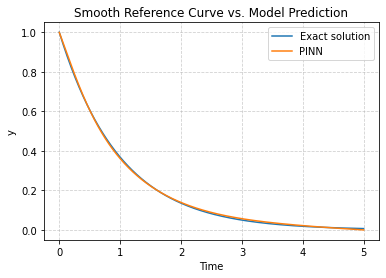

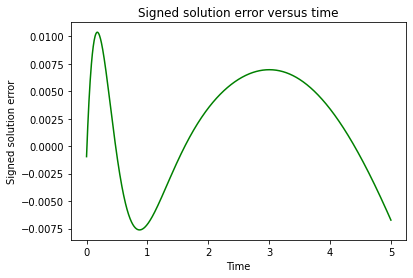

In [8]:
## Evaluation of the model

# Generating evaluation points outside the collocation points but in the same domain
t_eval = torch.linspace(0.0, 5.0, 1001).reshape(-1, 1)

# Evaluating model on these points and comparing with exact solution e^{-t}
model.eval()
with torch.no_grad():
    u_eval = model(t_eval)

u_exact = torch.exp(-t_eval)

# Signed solution error

solerrors = u_eval-u_exact

# MSE error

MSE = torch.mean(solerrors**2)

# Maximum absolute sampled error

E_max = torch.max(torch.abs(solerrors))

# Discrete relative L2 error

E_rel = torch.sqrt(torch.sum(solerrors**2))/torch.sqrt(torch.sum(u_exact**2))

print("MSE: "+str(MSE)+" , E_max: "+str(E_max)+" , E_rel: "+str(E_rel))

# Plotting the predicted output versus true output
plt.plot(t_eval[:, 0], u_exact[:, 0], label="Exact solution")
plt.plot(t_eval[:, 0], u_eval[:, 0], label="PINN")
plt.title('Smooth Reference Curve vs. Model Prediction')
plt.xlabel('Time')
plt.ylabel('y')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

plt.show()

# Plotting the signed error versus time
plt.plot(t_eval[:, 0], solerrors[:, 0], color="green")
plt.title('Signed solution error versus time')
plt.xlabel('Time')
plt.ylabel('Signed solution error')

plt.show()

Evidently, the model does a very good job of predicting the true function. To further improve the accuracy we could train on more epochs. But clearly, the signed solution error is very low, indicating a successful neural network. Technically, we could stop here as the overarching goal of having a small solution error has been achieved. But for the sake of learning, we are going to check the equation residual between the collocation points. In true training, if we have a small equation residual and small initial residual, this implies a small solution error. As such, if our solution error wasn't small and the function did not fit well, we could work backwards and check these individually to determine where the model is failing. Namely, is it not accurately matching the differential equation or the initial condition. The equation residual simply tells us how well the model is able to pick the family of functions that describe the IVP, namely, how well does it recognise the solution is a member of the family of differential equations with solution governed by $Ce^{-t}$. The initial condition residual checks whether the model recognises the initial condition, namely, that $C=1$ in this case. 

So for the proceeding cell we are calculating the equation residual for the model, which is given by the equation:
$$ r_{eval} = u'_\theta(t)+u_\theta(t)$$

We already have $u_\theta(t)$, so we need to calculate $u'_\theta(t)$.

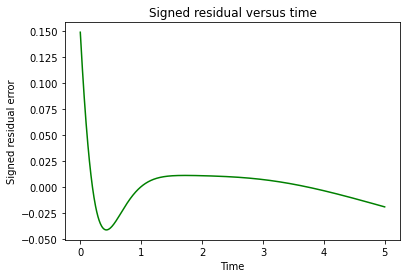

Dense-grid residual MSE: 0.00043158964741554947
Last recorded collocation residual MSE: 0.0003592627938411654
Maximum sampled absolute residual: 0.148787478641082


In [13]:
## Equation residual check between collocation points

t_res = t_eval.detach().clone().requires_grad_(True)

model.eval()
u_res = model(t_res)

du_res_dt = torch.autograd.grad(
    outputs=u_res,
    inputs=t_res,
    grad_outputs=torch.ones_like(u_res),
    create_graph=False,)[0] # Evaluate the derivative; no further differentiation through it needed.
# Equation residual
r_eval = du_res_dt + u_res

# MSE error

R_eval = torch.mean(r_eval**2)

# Maximum absolute residual

R_max = torch.max(torch.abs(r_eval))

# Plot of signed residual against time
plt.plot(t_res.detach().numpy()[:, 0], r_eval.detach().numpy()[:, 0], color="green")
plt.title('Signed residual versus time')
plt.xlabel('Time')
plt.ylabel('Signed residual error')

plt.show()

# Comparison of dense-grid MSE versus final loss

print("Dense-grid residual MSE:", R_eval.item())
print("Last recorded collocation residual MSE:", eqvalues[-1])
print("Maximum sampled absolute residual:", R_max.item())

## Playing around with model variables

We will play around with the model a little bit now to see what changing various variables does. We will start by adjusting the number of collocation points from $N=32$ to $N=128$, keeping everything else fixed. Going to copy the model initialisation and training code into the cell below, to run it all at once. We then proceed to increase the number of epochs and vary the bias on the initial condition loss by varying $\lambda_0$ in:
$$ \mathcal{L} = \mathcal{L}_eq + \lambda_0\mathcal{L}_0$$
We will try $\lambda_0=100$ and $\lambda_0=0.01$.

Equation loss: 0.08628274478408096 -> 2.583945685196198e-07
Initial loss: 1.766555376667937 -> 1.653934180063441e-08
Total loss: 0.10394829855076033 -> 2.5855996193762616e-07
Final initial prediction: 0.9998724056831361
MSE: tensor(6.5662e-09) , E_max: tensor(0.0002) , E_rel: tensor(0.0003)


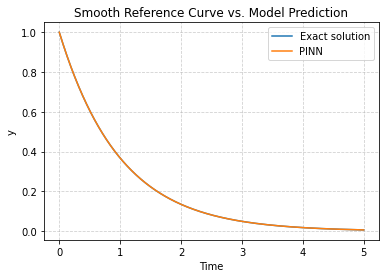

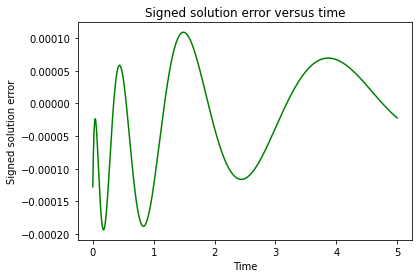

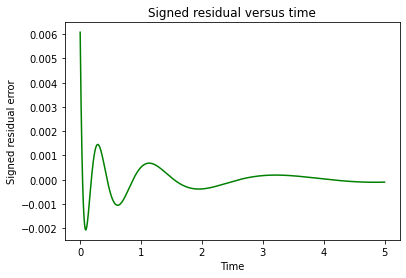

Dense-grid residual MSE: 3.0931889123843053e-07
Last recorded collocation residual MSE: 2.583945685196198e-07
Maximum sampled absolute residual: 0.006080494634515876


In [24]:
## Model architecture and differential and initial condition residuals

torch.manual_seed(0)

class PINN(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(1, 16),
            nn.Tanh(),
            nn.Linear(16, 16),
            nn.Tanh(),
            nn.Linear(16, 1)
        )
        
    def forward(self, x):
        return self.network(x)

# Mean squared differential-equation residual
def mseresidual(du_dt, u_pred):
    return torch.mean((du_dt+u_pred)**2)

# Computing the initial input. We will simply call the model on our initial condition t_0=0

t0 = torch.zeros((1,1))

# Loss of the initial condition. We compute the mean so that it returns a scalar, same as L_eq.

def lossinit(u0):
    return ((u0-1)**2).mean()

## Training

# Creates 128 collocation points that are the midpoints of the 128 partitions splitting up [0,5]

collpoints = torch.reshape(torch.arange(start=5/(2*128), end=5, step=5/128, dtype=torch.float64),(128,1))
collpoints.requires_grad_(True)

torch.manual_seed(0)
model=PINN()

params = tuple(model.parameters())
optimiser = torch.optim.Adam(params, lr=1e-3)

eqvalues=[]
initvalues=[]
lossvalues=[]
lambda_init = 0.01

# Training loop

for epoch in range(5000):
    model.train()
    optimiser.zero_grad()
    ucoll = model(collpoints)
    # Recomputes gradient of collocation points
    ducoll_dt = torch.autograd.grad(
        outputs=ucoll,
        inputs=collpoints,
        grad_outputs=torch.ones_like(ucoll),
        create_graph=True,)[0]
    # Recomputes initial condition
    u0 = model(t0)
    # Loss of current model
    loss = mseresidual(ducoll_dt, ucoll) + lambda_init*lossinit(u0)
    loss.backward(inputs=params)
    optimiser.step()
    eqvalues.append(mseresidual(ducoll_dt, ucoll).item())
    initvalues.append(lossinit(u0).item())
    lossvalues.append(loss.item())

print("Equation loss:", eqvalues[0], "->", eqvalues[-1])
print("Initial loss:", initvalues[0], "->", initvalues[-1])
print("Total loss:", lossvalues[0], "->", lossvalues[-1])
print("Final initial prediction:", model(t0).item())

## Evaluation of the model

# Generating evaluation points outside the collocation points but in the same domain
t_eval = torch.linspace(0.0, 5.0, 1001).reshape(-1, 1)

# Evaluating model on these points and comparing with exact solution e^{-t}
model.eval()
with torch.no_grad():
    u_eval = model(t_eval)

u_exact = torch.exp(-t_eval)

# Signed solution error

solerrors = u_eval-u_exact

# MSE error

MSE = torch.mean(solerrors**2)

# Maximum absolute sampled error

E_max = torch.max(torch.abs(solerrors))

# Discrete relative L2 error

E_rel = torch.sqrt(torch.sum(solerrors**2))/torch.sqrt(torch.sum(u_exact**2))

print("MSE: "+str(MSE)+" , E_max: "+str(E_max)+" , E_rel: "+str(E_rel))

# Plotting the predicted output versus true output
plt.plot(t_eval[:, 0], u_exact[:, 0], label="Exact solution")
plt.plot(t_eval[:, 0], u_eval[:, 0], label="PINN")
plt.title('Smooth Reference Curve vs. Model Prediction')
plt.xlabel('Time')
plt.ylabel('y')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

plt.show()

# Plotting the signed error versus time
plt.plot(t_eval[:, 0], solerrors[:, 0], color="green")
plt.title('Signed solution error versus time')
plt.xlabel('Time')
plt.ylabel('Signed solution error')

plt.show()

## Equation residual check between collocation points

t_res = t_eval.detach().clone().requires_grad_(True)

model.eval()
u_res = model(t_res)

du_res_dt = torch.autograd.grad(
    outputs=u_res,
    inputs=t_res,
    grad_outputs=torch.ones_like(u_res),
    create_graph=False,)[0] # Evaluate the derivative; no further differentiation through it needed.
# Equation residual
r_eval = du_res_dt + u_res

# MSE error

R_eval = torch.mean(r_eval**2)

# Maximum absolute residual

R_max = torch.max(torch.abs(r_eval))

# Plot of signed residual against time
plt.plot(t_res.detach().numpy()[:, 0], r_eval.detach().numpy()[:, 0], color="green")
plt.title('Signed residual versus time')
plt.xlabel('Time')
plt.ylabel('Signed residual error')

plt.show()

# Comparison of dense-grid MSE versus final loss

print("Dense-grid residual MSE:", R_eval.item())
print("Last recorded collocation residual MSE:", eqvalues[-1])
print("Maximum sampled absolute residual:", R_max.item())

## Results of changes

Increasing the midpoint count from 32 to 128, with initialisation and update count fixed, modestly improved solution accuracy and residual satisfaction. This experiment does not establish that increasing collocation density always improves accuracy. Moreover, we still see a residual peak near $t=0$. We will change the number of runs to 5000 and test. We will do this in the same above code.

Evidently, increasing the number of runs has drastically improved the model. Because the architecture, collocation points, and loss weights remained fixed, this experiment demonstrates that the existing network could achieve substantially better accuracy through additional optimisation. The earlier errors did not establish a capacity limitation.

Changing the initial condition parameter majorly increased the efficacy of the model. Specifically, for $\lambda_0=0.01$ we saw a solution error on order of 100 times better than the previous training models. This not only demonstrates the efficacy of the model but points largely to the fact that initial condition for this IVP was not as important. Setting it's bias low produced a more positive result.

Importantly, these experiments illustrate that changing the variables of the model can lead to profound changes. For a PINN we have the addition of biases for the IVP losses too. 

## Making the notebook reproducible

The aim of this next cell is to wrap the training block into a function that we can call so that it is completely reproducible. We will copy over the architecture initialisation block so it is all grouped together. 

In [27]:
## Model architecture and differential and initial condition residuals

torch.set_default_dtype(torch.float64)
torch.manual_seed(0)

class PINN(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(1, 16),
            nn.Tanh(),
            nn.Linear(16, 16),
            nn.Tanh(),
            nn.Linear(16, 1)
        )
        
    def forward(self, x):
        return self.network(x)

# Mean squared differential-equation residual
def mseresidual(du_dt, u_pred):
    return torch.mean((du_dt+u_pred)**2)

# Loss of the initial condition. We compute the mean so that it returns a scalar, same as L_eq.

def lossinit(u0):
    return ((u0-1)**2).mean()

## Training

def train_pinn(N, steps, lambda_init, lr=1e-3, seed=0, T=5.0,):
    # Initialisation of collocation points
    collpoints = ((torch.arange(N, dtype=torch.float64) + 0.5) * (T / N)).reshape(N, 1).requires_grad_(True)

    torch.manual_seed(seed)
    model=PINN()

    params = tuple(model.parameters())
    optimiser = torch.optim.Adam(params, lr)
    
    # Initial condition
    t0 = torch.zeros((1, 1), dtype=torch.float64)
    
    # Dictionary of history to keep track of losses
    history = {
        "equation": [], # Equation residual loss
        "initial": [], # Initial condition loss
        "total": [] # Weighted total loss
    }

    # Training loop

    for epoch in range(steps):
        model.train()
        optimiser.zero_grad()
        ucoll = model(collpoints)
        # Recomputes gradient of collocation points
        ducoll_dt = torch.autograd.grad(
            outputs=ucoll,
            inputs=collpoints,
            grad_outputs=torch.ones_like(ucoll),
            create_graph=True,)[0]
        # Recomputes initial condition
        u0 = model(t0)
        # Loss of current model
        L_eq = mseresidual(ducoll_dt, ucoll)
        L_init = lossinit(u0)
        loss = L_eq + lambda_init*L_init
        loss.backward(inputs=params)
        optimiser.step()
        history["equation"].append(L_eq.item())
        history["initial"].append(L_init.item())
        history["total"].append(loss.item())
        
    return model, history

In [31]:
model, history = train_pinn(
    N=128,
    steps=5000,
    lambda_init=0.01,
    lr=1e-3,
    seed=0,
    T=5.0,
)

print({name: values[-1] for name, values in history.items()})

{'equation': 2.583945685196198e-07, 'initial': 1.653934180063441e-08, 'total': 2.5855996193762616e-07}
